UPLOAD pest.zip


Saving archive.zip to archive.zip
UPLOAD pest_info.json


Saving pest_info.json to pest_info.json

FILES READY
Dataset ZIP: /content/archive.zip
Knowledge Base: /content/pest_info.json

Knowledge base loaded successfully!
Number of classes: 9

Extracting dataset...
Dataset extracted successfully!

==============================$$
PEST CLASSES
==============================$$
0 -> aphids
1 -> armyworm
2 -> beetle
3 -> bollworm
4 -> grasshopper
5 -> mites
6 -> mosquito
7 -> sawfly
8 -> stem_borer

Total Classes: 9

Loading training dataset...
Found 2700 files belonging to 9 classes.
Using 2160 files for training.

Loading validation dataset...
Found 2700 files belonging to 9 classes.
Using 540 files for validation.

Loading test dataset...
Found 450 files belonging to 9 classes.

Loading EfficientNetB0...
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Model created successfully!


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,700 (16.08 MB)

 Trainable params: 165,129 (645.04 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


==============================$$
TRAINING MODEL
==============================$$
Epoch 1/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 188s 3s/step - accuracy: 0.6611 - loss: 1.0453 - val_accuracy: 0.6944 - val_loss: 0.7077 - learning_rate: 0.0010
Epoch 2/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 202s 3s/step - accuracy: 0.8778 - loss: 0.3922 - val_accuracy: 0.9500 - val_loss: 0.2933 - learning_rate: 0.0010
Epoch 3/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 198s 3s/step - accuracy: 0.9380 - loss: 0.2412 - val_accuracy: 0.9556 - val_loss: 0.1936 - learning_rate: 0.0010
Epoch 4/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 190s 3s/step - accuracy: 0.9431 - loss: 0.1838 - val_accuracy: 0.9833 - val_loss: 0.1271 - learning_rate: 0.0010
Epoch 5/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 200s 3s/step - accuracy: 0.9551 - loss: 0.1483 - val_accuracy: 0.9889 - val_loss: 0.0938 - learning_rate: 0.0010
Epoch 6/10
68/68 ━━━━━━━━━━━━━━━━━━━━ 202s 3s/step - accuracy: 0.9722 - loss: 0.1111 - val_accuracy: 0.9778 - val_loss: 0.1028 - learning_rate: 0.0010
Epoch 7/10
6

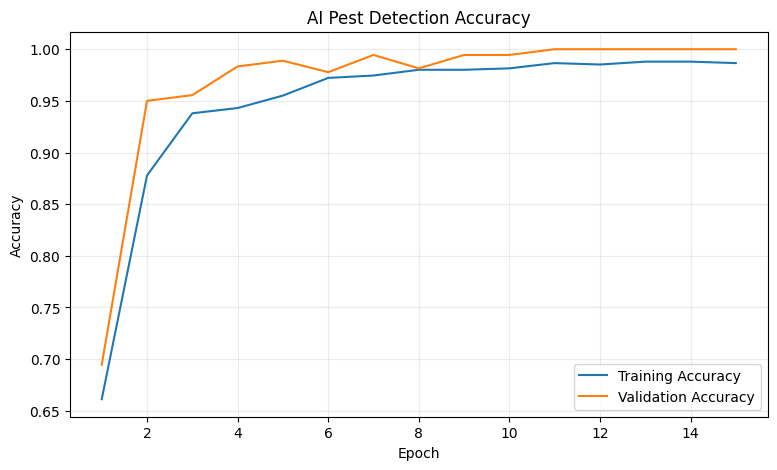

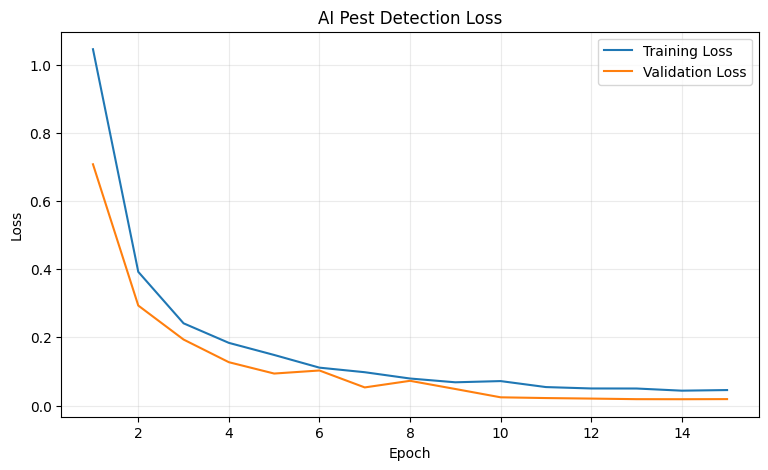


Model saved at:
/content/pest_detection_enhanced.keras

🚀 LAUNCHING AI PEST DETECTION SYSTEM
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://7e954c9ee8ec93da46.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import os
import json
import zipfile
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import gradio as gr

from pathlib import Path
from PIL import Image

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input


# ============================================================
# 3. UPLOAD FILES ONLY IF THEY ARE NOT ALREADY PRESENT
# ============================================================

import os
import glob
from google.colab import files

# Look for existing ZIP file
zip_files = glob.glob("/content/*.zip")

# Look for existing JSON file
json_files = glob.glob("/content/*.json")

# ------------------------------------------------------------
# Upload ZIP only if it does not already exist
# ------------------------------------------------------------

if len(zip_files) == 0:

    print("=" * 60)
    print("UPLOAD pest.zip")
    print("=" * 60)

    uploaded_zip = files.upload()

    zip_files = glob.glob("/content/*.zip")

else:

    print("✅ pest.zip already exists. Skipping upload.")


# ------------------------------------------------------------
# Upload JSON only if it does not already exist
# ------------------------------------------------------------

if len(json_files) == 0:

    print("=" * 60)
    print("UPLOAD pest_info.json")
    print("=" * 60)

    uploaded_json = files.upload()

    json_files = glob.glob("/content/*.json")

else:

    print("✅ pest_info.json already exists. Skipping upload.")


# ------------------------------------------------------------
# Get file paths
# ------------------------------------------------------------

if len(zip_files) == 0:
    raise FileNotFoundError("No .zip file found in /content.")

if len(json_files) == 0:
    raise FileNotFoundError("No .json file found in /content.")

zip_path = zip_files[0]
json_path = json_files[0]

print("\n========================================")
print("FILES READY")
print("========================================")

print("Dataset ZIP:", zip_path)
print("Knowledge Base:", json_path)


# ============================================================
# 4. LOAD PEST KNOWLEDGE BASE
# ============================================================

with open(
    json_path,
    "r",
    encoding="utf-8"
) as file:

    pest_info = json.load(file)


print("\nKnowledge base loaded successfully!")

print(
    "Number of classes:",
    pest_info["metadata"]["dataset_classes"]
)


# ============================================================
# 5. EXTRACT DATASET
# ============================================================

EXTRACT_PATH = "/content"

DATASET_PATH = "/content/pest"


if not os.path.exists(DATASET_PATH):

    print("\nExtracting dataset...")

    with zipfile.ZipFile(
        zip_path,
        "r"
    ) as zip_ref:

        zip_ref.extractall(
            EXTRACT_PATH
        )

    print("Dataset extracted successfully!")

else:

    print(
        "\nDataset already extracted."
    )


TRAIN_PATH = os.path.join(
    DATASET_PATH,
    "train"
)

TEST_PATH = os.path.join(
    DATASET_PATH,
    "test"
)


if not os.path.exists(TRAIN_PATH):

    raise FileNotFoundError(
        "Training folder not found."
    )


if not os.path.exists(TEST_PATH):

    raise FileNotFoundError(
        "Testing folder not found."
    )


# ============================================================
# 6. DETECT CLASS NAMES
# ============================================================

class_names = sorted([

    folder

    for folder in os.listdir(
        TRAIN_PATH
    )

    if os.path.isdir(
        os.path.join(
            TRAIN_PATH,
            folder
        )
    )

])


NUM_CLASSES = len(
    class_names
)


print("\n==============================$$")
print("PEST CLASSES")
print("==============================$$")

for i, name in enumerate(
    class_names
):

    print(
        i,
        "->",
        name
    )


print(
    "\nTotal Classes:",
    NUM_CLASSES
)


# ============================================================
# 7. PARAMETERS
# ============================================================

IMG_SIZE = (
    224,
    224
)

BATCH_SIZE = 32

SEED = 42


# ============================================================
# 8. LOAD TRAINING DATA
# ============================================================

print("\nLoading training dataset...")


train_ds = tf.keras.utils.image_dataset_from_directory(

    TRAIN_PATH,

    labels="inferred",

    label_mode="int",

    class_names=class_names,

    validation_split=0.20,

    subset="training",

    seed=SEED,

    image_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    shuffle=True

)


# ============================================================
# 9. LOAD VALIDATION DATA
# ============================================================

print("\nLoading validation dataset...")


validation_ds = tf.keras.utils.image_dataset_from_directory(

    TRAIN_PATH,

    labels="inferred",

    label_mode="int",

    class_names=class_names,

    validation_split=0.20,

    subset="validation",

    seed=SEED,

    image_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    shuffle=False

)


# ============================================================
# 10. LOAD TEST DATA
# ============================================================

print("\nLoading test dataset...")


test_ds = tf.keras.utils.image_dataset_from_directory(

    TEST_PATH,

    labels="inferred",

    label_mode="int",

    class_names=class_names,

    image_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    shuffle=False

)


# ============================================================
# 11. SPEED UP DATA PIPELINE
# ============================================================

AUTOTUNE = tf.data.AUTOTUNE


train_ds = train_ds.prefetch(
    AUTOTUNE
)

validation_ds = validation_ds.prefetch(
    AUTOTUNE
)

test_ds = test_ds.prefetch(
    AUTOTUNE
)


# ============================================================
# 12. DATA AUGMENTATION
# ============================================================

data_augmentation = tf.keras.Sequential([

    layers.RandomFlip(
        "horizontal"
    ),

    layers.RandomRotation(
        0.10
    ),

    layers.RandomZoom(
        0.10
    ),

    layers.RandomContrast(
        0.10
    )

])


# ============================================================
# 13. LOAD EFFICIENTNETB0
# ============================================================

print("\nLoading EfficientNetB0...")


base_model = EfficientNetB0(

    include_top=False,

    weights="imagenet",

    input_shape=(
        224,
        224,
        3
    )

)


base_model.trainable = False


# ============================================================
# 14. BUILD MODEL
# ============================================================

inputs = layers.Input(

    shape=(
        224,
        224,
        3
    )

)

x = data_augmentation(
    inputs
)

x = preprocess_input(
    x
)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(
    x
)

x = layers.Dropout(
    0.35
)(
    x
)

x = layers.Dense(
    128,
    activation="relu"
)(
    x
)

x = layers.Dropout(
    0.20
)(
    x
)


outputs = layers.Dense(

    NUM_CLASSES,

    activation="softmax"

)(
    x
)


model = models.Model(

    inputs=inputs,

    outputs=outputs

)


# ============================================================
# 15. COMPILE MODEL
# ============================================================

model.compile(

    optimizer=tf.keras.optimizers.Adam(

        learning_rate=0.001

    ),

    loss="sparse_categorical_crossentropy",

    metrics=[
        "accuracy"
    ]

)


print("\nModel created successfully!")


# ============================================================
# 16. MODEL SUMMARY
# ============================================================

model.summary()


# ============================================================
# 17. CALLBACKS
# ============================================================

callbacks = [

    tf.keras.callbacks.EarlyStopping(

        monitor="val_loss",

        patience=3,

        restore_best_weights=True

    ),

    tf.keras.callbacks.ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.3,

        patience=2,

        min_lr=0.0000001

    )

]


# ============================================================
# 18. TRAIN MODEL
# ============================================================

EPOCHS = 10


print("\n==============================$$")
print("TRAINING MODEL")
print("==============================$$")


history = model.fit(

    train_ds,

    validation_data=validation_ds,

    epochs=EPOCHS,

    callbacks=callbacks

)


# ============================================================
# 19. FINE TUNING
# ============================================================

print("\n==============================$$")
print("FINE TUNING MODEL")
print("==============================$$")


base_model.trainable = True


# Freeze most EfficientNet layers
for layer in base_model.layers[:-30]:

    layer.trainable = False


# Keep BatchNormalization layers frozen
for layer in base_model.layers:

    if isinstance(
        layer,
        layers.BatchNormalization
    ):

        layer.trainable = False


model.compile(

    optimizer=tf.keras.optimizers.Adam(

        learning_rate=0.00001

    ),

    loss="sparse_categorical_crossentropy",

    metrics=[
        "accuracy"
    ]

)


fine_history = model.fit(

    train_ds,

    validation_data=validation_ds,

    epochs=5,

    callbacks=callbacks

)


# ============================================================
# 20. TEST MODEL
# ============================================================

test_loss, test_accuracy = model.evaluate(

    test_ds,

    verbose=1

)


print("\n==============================$$")
print("FINAL MODEL PERFORMANCE")
print("==============================$$")


print(

    "Test Accuracy:",

    round(
        test_accuracy * 100,
        2
    ),

    "%"

)


print(

    "Test Loss:",

    round(
        test_loss,
        4
    )

)


# ============================================================
# 21. COMBINE TRAINING HISTORY
# ============================================================

accuracy = (

    history.history["accuracy"]

    +

    fine_history.history["accuracy"]

)


validation_accuracy = (

    history.history["val_accuracy"]

    +

    fine_history.history["val_accuracy"]

)


loss = (

    history.history["loss"]

    +

    fine_history.history["loss"]

)


validation_loss = (

    history.history["val_loss"]

    +

    fine_history.history["val_loss"]

)


epochs_range = range(

    1,
    len(accuracy) + 1

)


# ============================================================
# 22. ACCURACY GRAPH
# ============================================================

plt.figure(
    figsize=(9,5)
)


plt.plot(

    epochs_range,

    accuracy,

    label="Training Accuracy"

)


plt.plot(

    epochs_range,

    validation_accuracy,

    label="Validation Accuracy"

)


plt.title(
    "AI Pest Detection Accuracy"
)


plt.xlabel(
    "Epoch"
)


plt.ylabel(
    "Accuracy"
)


plt.legend()


plt.grid(
    alpha=0.25
)


plt.show()


# ============================================================
# 23. LOSS GRAPH
# ============================================================

plt.figure(
    figsize=(9,5)
)


plt.plot(

    epochs_range,

    loss,

    label="Training Loss"

)


plt.plot(

    epochs_range,

    validation_loss,

    label="Validation Loss"

)


plt.title(
    "AI Pest Detection Loss"
)


plt.xlabel(
    "Epoch"
)


plt.ylabel(
    "Loss"
)


plt.legend()


plt.grid(
    alpha=0.25
)


plt.show()


# ============================================================
# 24. SAVE MODEL
# ============================================================

MODEL_PATH = (

    "/content/"
    "pest_detection_enhanced.keras"

)


model.save(
    MODEL_PATH
)


print(
    "\nModel saved at:"
)

print(
    MODEL_PATH
)


# ============================================================
# 25. KNOWLEDGE BASE HELPER
# ============================================================

def get_pest_information(
    pest_class
):

    pests = pest_info.get(
        "pests",
        {}
    )

    if pest_class in pests:

        return pests[pest_class]

    else:

        return {

            "common_name":
                pest_class.replace(
                    "_",
                    " "
                ).title(),

            "category":
                "Information unavailable",

            "description":
                "No description available.",

            "visual_characteristics":
                [],

            "symptoms":
                [],

            "commonly_affected_crops":
                [],

            "prevention":
                [],

            "physical_cultural_control":
                [],

            "biological_control":
                [],

            "chemical_control_note":
                "Confirm pest identity before selecting treatment.",

            "monitoring":
                "Perform field monitoring.",

            "severity_guidance":
                "Do not use model confidence as severity."

        }


# ============================================================
# 26. BULLET FORMAT FUNCTION
# ============================================================

def make_bullets(
    items
):

    if not items:

        return "Not available."

    return "\n".join(

        [
            "• " + str(item)

            for item in items

        ]

    )


# ============================================================
# 27. PEST PREDICTION FUNCTION
# ============================================================

def predict_pest(
    image
):

    if image is None:

        return (
            "Please upload a pest image."
        )


    try:

        # --------------------------------
        # Convert image to RGB
        # --------------------------------

        image = image.convert(
            "RGB"
        )


        # --------------------------------
        # Resize image
        # --------------------------------

        image = image.resize(
            IMG_SIZE
        )


        # --------------------------------
        # Convert to NumPy
        # --------------------------------

        img_array = np.array(
            image
        ).astype(
            "float32"
        )


        # --------------------------------
        # Add batch dimension
        # --------------------------------

        img_array = np.expand_dims(

            img_array,

            axis=0

        )


        # --------------------------------
        # Predict
        # --------------------------------

        predictions = model.predict(

            img_array,

            verbose=0

        )[0]


        # --------------------------------
        # Predicted class
        # --------------------------------

        predicted_index = int(

            np.argmax(
                predictions
            )

        )


        predicted_class = (

            class_names[
                predicted_index
            ]

        )


        confidence = (

            predictions[
                predicted_index
            ]

            * 100

        )


        # --------------------------------
        # Get knowledge base information
        # --------------------------------

        info = get_pest_information(

            predicted_class

        )


        # --------------------------------
        # Top 3 predictions
        # --------------------------------

        top_indices = (

            np.argsort(
                predictions
            )[-3:][::-1]

        )


        # ====================================================
        # BUILD FINAL OUTPUT
        # ====================================================

        result = ""


        result += (
            "🌱 AI PEST DETECTION RESULT\n"
        )

        result += (
            "========================================\n\n"
        )


        # --------------------------------
        # Pest name
        # --------------------------------

        result += (

            "🐛 DETECTED PEST\n"

        )

        result += (

            f"{info.get('common_name', predicted_class)}\n\n"

        )


        # --------------------------------
        # Confidence
        # --------------------------------

        result += (

            "🎯 CONFIDENCE\n"

        )

        result += (

            f"{confidence:.2f}%\n\n"

        )


        # --------------------------------
        # Category
        # --------------------------------

        result += (

            "🏷️ CATEGORY\n"

        )

        result += (

            f"{info.get('category', 'Not available')}\n\n"

        )


        # --------------------------------
        # DESCRIPTION
        # --------------------------------

        result += (

            "📌 DESCRIPTION\n"

        )

        result += (

            f"{info.get('description', 'Not available.')}\n\n"

        )


        # --------------------------------
        # VISUAL CHARACTERISTICS
        # --------------------------------

        result += (

            "🔍 VISUAL CHARACTERISTICS\n"

        )

        result += make_bullets(

            info.get(
                "visual_characteristics",
                []
            )

        )

        result += "\n\n"


        # --------------------------------
        # SYMPTOMS
        # --------------------------------

        result += (

            "🌿 COMMON SYMPTOMS\n"

        )

        result += make_bullets(

            info.get(
                "symptoms",
                []
            )

        )

        result += "\n\n"


        # --------------------------------
        # AFFECTED CROPS
        # --------------------------------

        result += (

            "🌾 COMMONLY AFFECTED CROPS\n"

        )

        result += make_bullets(

            info.get(
                "commonly_affected_crops",
                []
            )

        )

        result += "\n\n"


        # --------------------------------
        # PREVENTION
        # --------------------------------

        result += (

            "🛡️ PREVENTION\n"

        )

        result += make_bullets(

            info.get(
                "prevention",
                []
            )

        )

        result += "\n\n"


        # --------------------------------
        # PHYSICAL / CULTURAL CONTROL
        # --------------------------------

        result += (

            "🧹 PHYSICAL / CULTURAL CONTROL\n"

        )

        result += make_bullets(

            info.get(
                "physical_cultural_control",
                []
            )

        )

        result += "\n\n"


        # --------------------------------
        # BIOLOGICAL CONTROL
        # --------------------------------

        result += (

            "🐞 BIOLOGICAL CONTROL\n"

        )

        result += make_bullets(

            info.get(
                "biological_control",
                []
            )

        )

        result += "\n\n"


        # --------------------------------
        # CHEMICAL CONTROL
        # --------------------------------

        result += (

            "🧪 CHEMICAL CONTROL NOTE\n"

        )

        result += (

            f"{info.get('chemical_control_note', 'Not available.')}\n\n"

        )


        # --------------------------------
        # MONITORING
        # --------------------------------

        result += (

            "🔎 MONITORING\n"

        )

        result += (

            f"{info.get('monitoring', 'Not available.')}\n\n"

        )


        # --------------------------------
        # SEVERITY
        # --------------------------------

        result += (

            "📊 SEVERITY GUIDANCE\n"

        )

        result += (

            f"{info.get('severity_guidance', 'Not available.')}\n\n"

        )


        # --------------------------------
        # TOP 3
        # --------------------------------

        result += (

            "📈 TOP 3 MODEL PREDICTIONS\n"

        )


        for rank, index in enumerate(

            top_indices,

            start=1

        ):

            result += (

                f"{rank}. "

                f"{class_names[index]}"

                f" : "

                f"{predictions[index] * 100:.2f}%\n"

            )


        result += "\n"


        # --------------------------------
        # IMPORTANT WARNING
        # --------------------------------

        result += (

            "⚠️ IMPORTANT\n"

        )

        result += (

            "This AI model predicts broad pest groups "
            "from the dataset. It should not be treated "
            "as guaranteed species-level identification. "
            "Model confidence is not a measurement of "
            "infestation severity. Field scouting, crop "
            "stage, pest identity and local agricultural "
            "guidance should be considered before "
            "management decisions."

        )


        return result


    except Exception as error:

        return (

            "Prediction error:\n"

            + str(error)

        )


# ============================================================
# 28. GRADIO INTERFACE
# ============================================================

interface_description = """

Upload a crop pest image.

The AI model will identify the most likely pest and
automatically retrieve its information from pest_info.json.

The system displays:

🐛 Pest name
🎯 Confidence
🏷️ Category
📌 Description
🔍 Visual characteristics
🌿 Symptoms
🌾 Commonly affected crops
🛡️ Prevention
🧹 Physical / cultural control
🐞 Biological control
🧪 Chemical-control note
🔎 Monitoring
📊 Severity guidance
📈 Top 3 predictions

The knowledge base is loaded from your uploaded pest_info.json.

Note:
The model predicts broad dataset pest groups.
Confidence should not be interpreted as infestation severity.
"""


demo = gr.Interface(

    fn=predict_pest,

    inputs=gr.Image(

        type="pil",

        label="📷 Upload Pest Image"

    ),

    outputs=gr.Textbox(

        label="🌱 AI Pest Detection Result",

        lines=35

    ),

    title=(
        "🌱 AI Pest Detection "
        "& Information System"
    ),

    description=interface_description,

    examples=None

)


# ============================================================
# 29. LAUNCH
# ============================================================

print("\n========================================")
print("🚀 LAUNCHING AI PEST DETECTION SYSTEM")
print("========================================")


demo.launch(

    share=True,

    debug=True

)
